In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# CONFIG 
DATA_PATH = "C:\\Thanvi\\academic\\Sem 5\\AUCML LAB\\ese\\Project\\india_zambia_clean.csv"   # path to your file
COUNTRY = "India"                      # "India" or "Zambia"
MAX_GAP = 3                            # fill gaps of up to this many months

COMMODITIES = {
    "India":  ["Onions", "Potatoes", "Tomatoes", "Rice"],
    "Zambia": ["Maize (white)", "Maize meal (white, roller)",
               "Groundnuts (shelled)", "Beans (dry)"],
}

In [24]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"], low_memory=False)

# The source labels India as "Bassas da India"
df["country"] = df["country"].replace({"Bassas da India": "India"})

# Keep Retail only so wholesale and retail prices are not mixed
df = df[df["price_type"] == "Retail"]

print(df.shape)
print(df["country"].value_counts())

(152108, 11)
country
India     111189
Zambia     40919
Name: count, dtype: int64


In [25]:
d = df[(df["country"] == COUNTRY) & (df["commodity"].isin(COMMODITIES[COUNTRY]))]

missing = set(COMMODITIES[COUNTRY]) - set(d["commodity"].unique())
if missing:
    print("WARNING, not found for this country:", missing)

currency = d["currency"].iloc[0]
print(f"{COUNTRY}: {len(d):,} rows, currency = {currency}")
print(d.groupby("commodity").agg(
    rows=("price", "size"),
    markets=("market", "nunique"),
    start=("date", "min"),
    end=("date", "max"),
))

India: 26,489 rows, currency = INR
           rows  markets      start        end
commodity                                     
Onions     5869       60 2000-01-01 2020-06-01
Potatoes   5905       60 2000-01-01 2020-06-01
Rice       9473       60 1994-01-01 2020-06-01
Tomatoes   5242       60 2012-04-01 2020-06-01


In [26]:
monthly = (
    d.groupby(["commodity", "date"])
     .agg(price=("price", "median"), n_markets=("market", "nunique"))
     .reset_index()
)
monthly.head()

,commodity,date,price,n_markets
0,Onions,2000-01-01,7.000,3
1,Onions,2000-02-01,5.740,3
2,Onions,2000-03-01,6.395,4
3,Onions,2000-04-01,6.130,4
4,Onions,2000-05-01,5.765,4


In [27]:
def fill_short_gaps(s, max_gap=2):
    """Linearly interpolate only NaN runs of length <= max_gap."""
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    run_len = isna.groupby(run_id).transform("sum")
    interp = s.interpolate(method="linear", limit_area="inside")
    fill_mask = isna & (run_len <= max_gap)
    out = s.copy()
    out[fill_mask] = interp[fill_mask]
    return out, fill_mask

def longest_gap(s):
    isna = s.isna()
    run_id = (isna != isna.shift()).cumsum()
    runs = isna.groupby(run_id).sum()
    return int(runs.max()) if len(runs) else 0

frames, report = [], []
for com, g in monthly.groupby("commodity"):
    g = g.set_index("date").sort_index()
    full_idx = pd.date_range(g.index.min(), g.index.max(), freq="MS")
    g = g.reindex(full_idx)

    n_missing_before = int(g["price"].isna().sum())
    g["price"], g["was_filled"] = fill_short_gaps(g["price"], MAX_GAP)

    report.append({
        "commodity": com,
        "start": g.index.min().date(),
        "end": g.index.max().date(),
        "months": len(g),
        "missing_before": n_missing_before,
        "filled": int(g["was_filled"].sum()),
        "still_missing": int(g["price"].isna().sum()),
        "longest_remaining_gap": longest_gap(g["price"]),
    })

    g["commodity"] = com
    g["country"] = COUNTRY
    g["currency"] = currency
    frames.append(g.rename_axis("date").reset_index())

clean = pd.concat(frames, ignore_index=True)
clean["n_markets"] = clean["n_markets"].fillna(0).astype(int)

pd.DataFrame(report)

,commodity,start,end,months,missing_before,filled,still_missing,longest_remaining_gap
0,Onions,2000-01-01,2020-06-01,246,0,0,0,0
1,Potatoes,2000-01-01,2020-06-01,246,0,0,0,0
2,Rice,1994-01-01,2020-06-01,318,0,0,0,0
3,Tomatoes,2012-04-01,2020-06-01,99,3,3,0,0


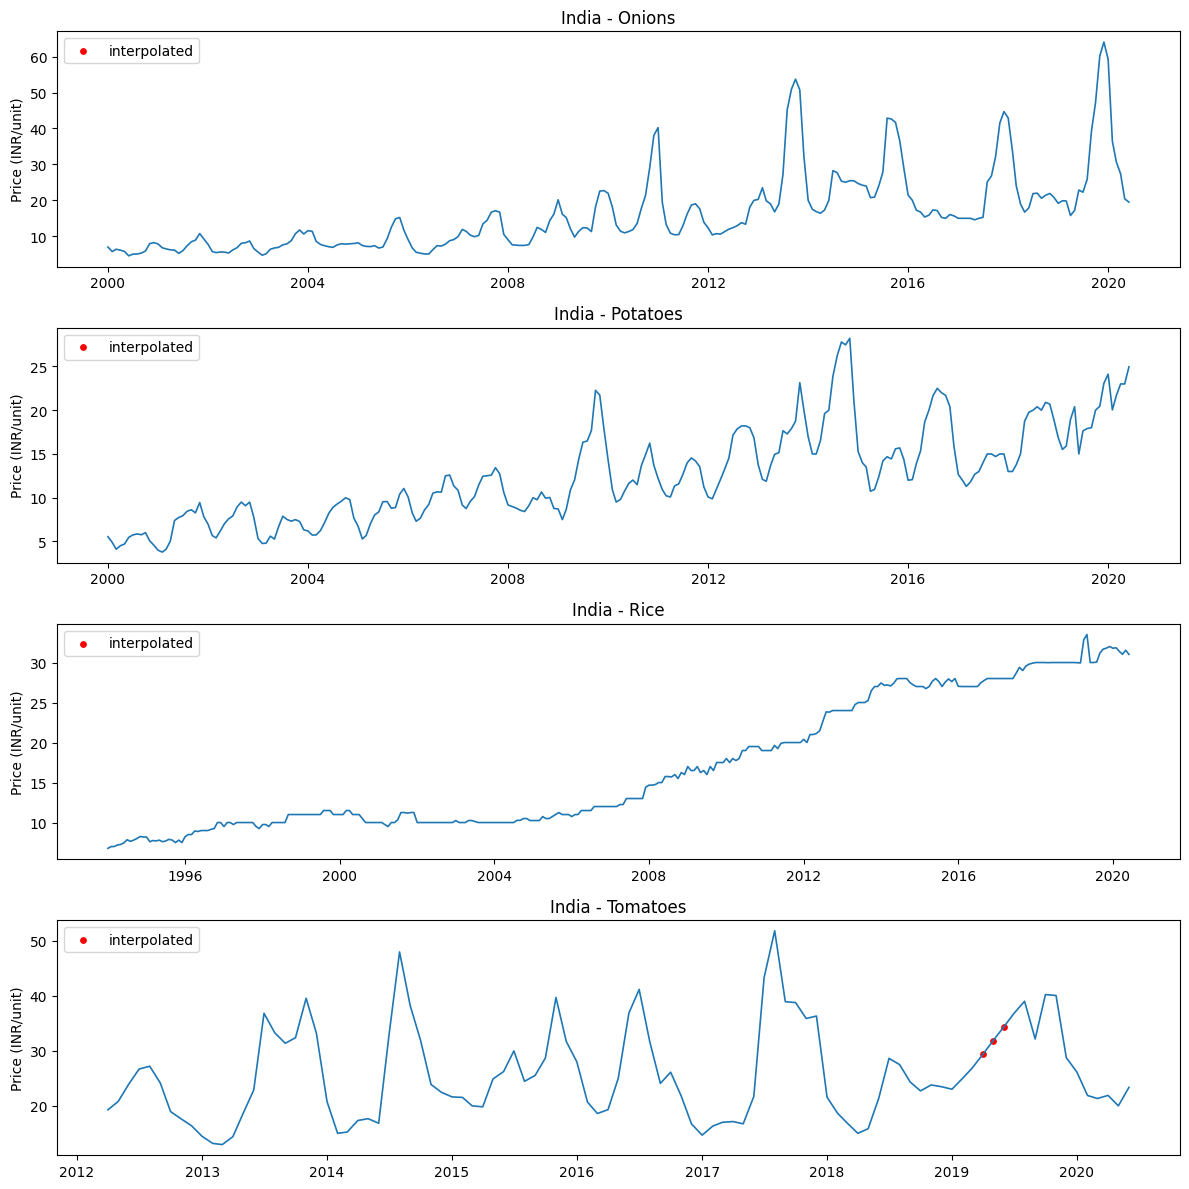

In [28]:
coms = clean["commodity"].unique()
fig, axes = plt.subplots(len(coms), 1, figsize=(12, 3 * len(coms)), sharex=False)
axes = np.atleast_1d(axes)

for ax, com in zip(axes, coms):
    s = clean[clean["commodity"] == com]
    ax.plot(s["date"], s["price"], lw=1.2)
    filled = s[s["was_filled"]]
    ax.scatter(filled["date"], filled["price"], color="red", s=15, label="interpolated")
    ax.set_title(f"{COUNTRY} - {com}")
    ax.set_ylabel(f"Price ({currency}/unit)")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

In [29]:
tom = clean[(clean["commodity"] == "Tomatoes") & (clean["price"].isna())]
print(tom["date"].dt.strftime("%Y-%m").tolist())

# context: prices around the gap
i = tom.index.min()
clean.loc[i-4:i+len(tom)+3, ["date", "price", "n_markets"]]

[]


,date,price,n_markets


In [30]:
out_path = f"clean_monthly_{COUNTRY.lower()}.csv"
clean.to_csv(out_path, index=False)
print("Saved", out_path, clean.shape)

Saved clean_monthly_india.csv (909, 7)
